# 07 · Base-Learner Study: T-learners on Random Forest, XGBoost and HistGradientBoosting

A T-learner estimates uplift as τ̂(x) = μ̂₁(x) − μ̂₀(x), with one outcome model per arm. *Which* regressor plays μ̂ is a modelling choice, and this notebook makes it on evidence.

| Role | Base learner | Implementation | Why it is in the study |
|---|---|---|---|
| **Baseline** | Random Forest | `sklearn.ensemble.RandomForestRegressor` | Bagging: robust, few knobs, hard to overfit. The reference to beat |
| **Primary candidate** | XGBoost | `xgboost.XGBRegressor` (scikit-learn API) | Regularized gradient boosting, the industry default for tabular data |
| **Efficiency benchmark** | HistGradientBoosting | `sklearn.ensemble.HistGradientBoostingRegressor` | Histogram boosting with early stopping; the project's default; the speed reference |

#### Protocol (fixed before results)
* **Same everything:** the same 12 pre-treatment features, the same splits, the same AIPW evaluation scores, and the same economics (35% margin, \$0.10 per e-mail, \$3k budget per 100k customers).
* **Same tuning budget:** 6 configurations per base learner (`src/benchmark.py: GRIDS`). Each is scored by the decision it will drive: **budgeted incremental profit** of the uplift policy, averaged over both campaigns.
* **Primary held-out evaluation: nested cross-validation over all 64,000 customers.**
  * 5 outer folds. In each, the configuration is chosen by 3-fold inner cross-validation on the training part only.
  * The chosen T-learner is refit, and the outer fold is scored and valued with AIPW scores computed *inside that fold*.
  * Every customer is held out exactly once, and no tuning decision sees its own evaluation data.
* **Secondary:** the original 20% test split from notebooks 02–06, with tuning on the development set only.
* **Winner rule:** highest pooled held-out profit at the \$3k budget, averaged over the two campaigns, reported with paired intervals against the Random Forest baseline.

*Disclosure:* the XGBoost round grid (50 / 200) was set after a smoke test showed 300 rounds over-dispersed its predictions. That keeps the comparison fair to the primary candidate.

In [1]:
import sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from src import benchmark as bm, config, data, evaluation, pipeline, plotting as P

P.use_style()
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 150)
df = data.load_raw()
X = data.build_features(df)
BASE_COLORS = {"Random Forest": P.ORANGE, "XGBoost": P.AQUA, "HistGradientBoosting": P.BLUE}
pd.DataFrame({"role": bm.ROLES, "name": bm.NAMES}).loc[bm.ORDER].join(
    pd.Series({b: "; ".join(bm.cfg_label(c) for c in g) for b, g in bm.GRIDS.items()}, name="tuning grid"))

,role,name,tuning grid
rf,Baseline,Random Forest,"min_samples_leaf=100, max_features=0.33; min_s..."
xgb,Primary candidate,XGBoost,"min_samples_leaf=100, n_estimators=50; min_sam..."
hgb,Efficiency benchmark,HistGradientBoosting,"min_samples_leaf=100, max_leaf_nodes=7; min_sa..."


## 1 · How each base learner works inside the T-learner

* **Random Forest (bagging).** It grows 300 deep trees, each on a random 50% of rows and considering a random subset of features at each split, then averages them. Averaging independent trees cuts variance without adding bias. Its outputs are local averages of real outcomes, so it cannot extrapolate to extreme values. Here that acts as natural shrinkage.
* **XGBoost (boosting with second-order optimization).** It adds shallow trees one at a time, each fitted to the gradient and Hessian of the loss left by the previous ones. It uses L2 penalties on leaf weights, a minimum Hessian per leaf (`min_child_weight` equals the minimum leaf size under squared loss), and row/column subsampling. It is powerful, but each round can fit residual noise, so the number of rounds is its key capacity knob.
* **HistGradientBoosting (histogram boosting).** This is the same boosting idea, but features are first binned into ≤ 255 histogram buckets, which makes splits very cheap. It has built-in early stopping on a 15% validation split.

All three plug into the same `TLearner` class through `base=`. Only the regressor changes.

## 2 · Primary evaluation: nested cross-validation over all 64,000 customers

In [2]:
t0 = time.time()
tau, gamma, chosen, timings = bm.nested_heldout(df, X, n_outer=5, n_inner=3, seed=config.SEED)
print(f"nested study finished in {time.time() - t0:.0f}s")
tau.to_csv(config.ARTIFACTS_DIR / "base_study_nested_tau.csv")
gamma.to_csv(config.ARTIFACTS_DIR / "base_study_nested_gamma.csv")
chosen.pivot(index="outer_fold", columns="base", values="config")[bm.ORDER].rename(columns=bm.NAMES)

outer fold 0: done in 58s


outer fold 1: done in 56s


outer fold 2: done in 57s


outer fold 3: done in 59s


outer fold 4: done in 56s
nested study finished in 289s


base,Random Forest,XGBoost,HistGradientBoosting
outer_fold,,,
0,"min_samples_leaf=400, max_features=0.33","min_samples_leaf=400, n_estimators=200","min_samples_leaf=400, max_leaf_nodes=7"
1,"min_samples_leaf=100, max_features=0.67","min_samples_leaf=400, n_estimators=50","min_samples_leaf=100, max_leaf_nodes=7"
2,"min_samples_leaf=200, max_features=0.67","min_samples_leaf=100, n_estimators=50","min_samples_leaf=400, max_leaf_nodes=7"
3,"min_samples_leaf=400, max_features=0.67","min_samples_leaf=400, n_estimators=200","min_samples_leaf=200, max_leaf_nodes=7"
4,"min_samples_leaf=100, max_features=0.33","min_samples_leaf=100, n_estimators=200","min_samples_leaf=200, max_leaf_nodes=7"


The table above shows the configuration chosen by the inner loop in each outer fold. If a base learner's choice changes from fold to fold, its performance is sensitive to tuning.

### 2a · Uplift ranking (held out)

In [3]:
rank = bm.ranking_table(tau, gamma)
rank.pivot(index="base", columns="campaign", values=["AUGC", "gain@30%", "BLP"]).loc[[bm.NAMES[b] for b in bm.ORDER]].round(4)

AUGC         gain@30%            BLP        
campaign                mens  womens     mens womens    mens  womens
base                                                                
Random Forest        -0.0572  0.0705   0.0610 0.1937 -0.3265  0.1505
XGBoost              -0.0403 -0.0117   0.1205 0.1333 -0.0764 -0.0079
HistGradientBoosting -0.0898  0.0518   0.0993 0.1957 -0.4267  0.0509

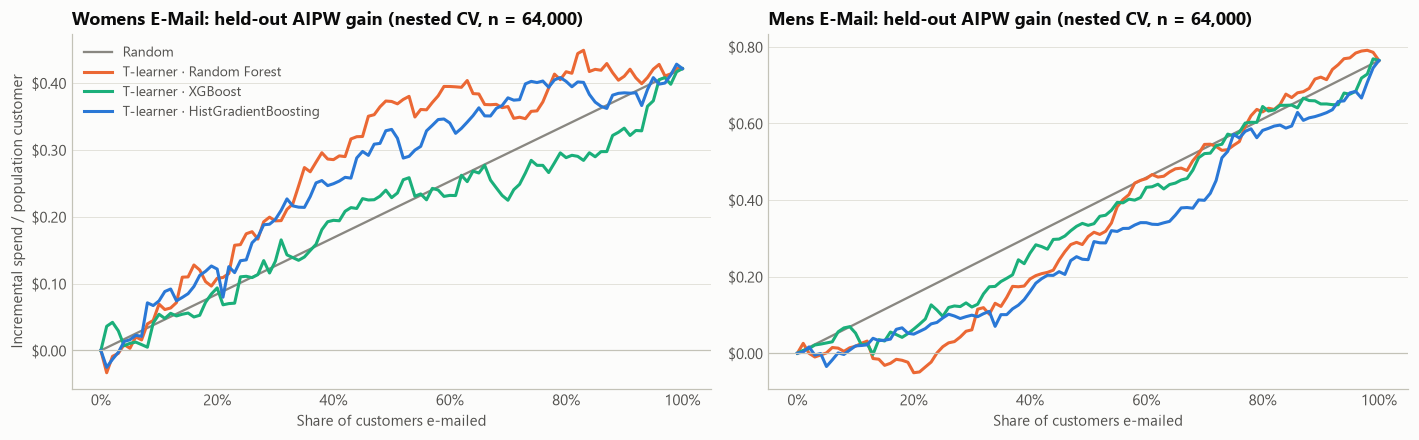

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.1))
for ax, camp in zip(axes, config.CAMPAIGNS):
    g = gamma[camp].to_numpy()
    ax.plot([0, 1], [0, g.mean()], color=P.MUTED, lw=1.5, label="Random")
    for b in bm.ORDER:
        ax.plot(evaluation.GRID, evaluation.gain_curve(tau[f"{b}|{camp}"].to_numpy(), g),
                color=BASE_COLORS[bm.NAMES[b]], lw=2, label=f"T-learner · {bm.NAMES[b]}")
    ax.axhline(0, color=P.AXIS, lw=0.8)
    P.percent(ax, "x"); P.dollar(ax)
    ax.set_xlabel("Share of customers e-mailed"); ax.set_title(f"{config.CAMPAIGNS[camp]}: held-out AIPW gain (nested CV, n = 64,000)")
axes[0].set_ylabel("Incremental spend / population customer"); axes[0].legend(loc="upper left")
fig.tight_layout(); P.savefig(fig, "07_nested_gain_curves"); plt.show()

### 2b · Incremental profit of the policy (the decision that matters)

Each T-learner drives the same uplift policy: e-mail a customer only when 0.35 × τ̂ > \$0.10, best first, until the budget is spent. The cells below show held-out AIPW profit per 100k customers, with paired differences against the Random Forest baseline.

In [5]:
pol = bm.policy_table(tau, gamma)
pol.to_csv(config.ARTIFACTS_DIR / "base_study_nested_policy.csv", index=False)
pol.set_index(["budget", "campaign", "base"]).style.format(
    {"coverage": "{:.0%}", "profit": P.money0, "ci_low": P.money0, "ci_high": P.money0, "vs_baseline": P.money0,
     "vs_ci_low": P.money0, "vs_ci_high": P.money0, "z": "{:.2f}"}, na_rep="—")

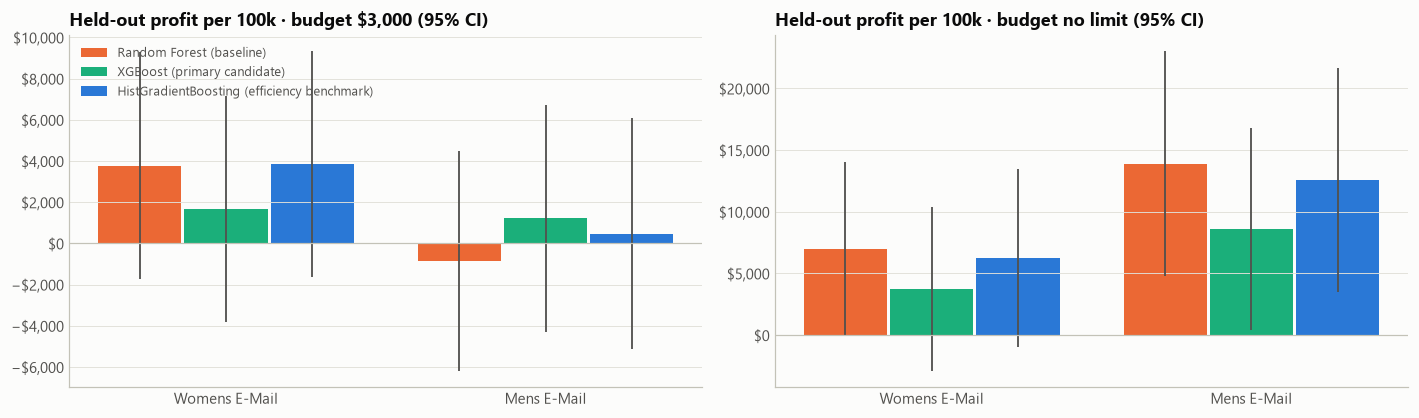

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.9), sharey=False)
for ax, budget in zip(axes, ["$3,000", "no limit"]):
    sub = pol[pol.budget == budget]
    camps = list(config.CAMPAIGNS)
    w = 0.26
    for j, b in enumerate(bm.ORDER):
        s = sub[sub.base == bm.NAMES[b]].set_index("campaign").loc[camps]
        x = np.arange(len(camps)) + (j - 1) * (w + 0.01)
        ax.bar(x, s.profit, width=w, color=BASE_COLORS[bm.NAMES[b]], label=f"{bm.NAMES[b]} ({bm.ROLES[b].lower()})")
        ax.vlines(x, s.ci_low, s.ci_high, color=P.INK_2, lw=1.2)
    ax.axhline(0, color=P.AXIS, lw=0.8)
    ax.set_xticks(range(len(camps)), [config.CAMPAIGNS[c] for c in camps])
    P.dollar(ax, "y", 0); ax.set_title(f"Held-out profit per 100k · budget {budget} (95% CI)")
axes[0].legend(loc="upper left", fontsize=8.5)
fig.tight_layout(); P.savefig(fig, "07_nested_policy_profit"); plt.show()

## 3 · Secondary evaluation: the original 20% test split

Tuning uses the 5 development folds from notebook 02 and their within-fold AIPW scores. The chosen T-learner is refit on the full development set and scored once on the test set.

In [7]:
splits = pd.read_csv(config.ARTIFACTS_DIR / "splits.csv", index_col=0)
dev_folds = splits["fold"]
dev, test = (splits["split"] == "dev").to_numpy(), (splits["split"] == "test").to_numpy()
g_dev = pd.read_csv(config.ARTIFACTS_DIR / "oof_gamma_spend.csv", index_col=0)
g_test = pipeline.evaluation_scores(df, X, test, seed=config.SEED)
tau_test, test_cfg, test_timings = pd.DataFrame(index=X.index[test]), {}, []
for b in bm.ORDER:
    table = bm.tune(df, X, dev_folds, g_dev, b, timings=test_timings)
    test_cfg[b] = table.loc[0, "cfg"]
    for camp in config.CAMPAIGNS:
        s, ft, pt = bm.fit_tlearner(df, X, dev, test, camp, b, test_cfg[b])
        tau_test[f"{b}|{camp}"] = s
display(pd.Series({bm.NAMES[b]: bm.cfg_label(c) for b, c in test_cfg.items()}, name="chosen on dev").to_frame())
pol_test = bm.policy_table(tau_test, g_test)
pol_test.to_csv(config.ARTIFACTS_DIR / "base_study_test_policy.csv", index=False)
rank_test = bm.ranking_table(tau_test, g_test)
pol_test.set_index(["budget", "campaign", "base"]).style.format(
    {"coverage": "{:.0%}", "profit": P.money0, "ci_low": P.money0, "ci_high": P.money0, "vs_baseline": P.money0,
     "vs_ci_low": P.money0, "vs_ci_high": P.money0, "z": "{:.2f}"}, na_rep="—")

,chosen on dev
Random Forest,"min_samples_leaf=400, max_features=0.67"
XGBoost,"min_samples_leaf=400, n_estimators=50"
HistGradientBoosting,"min_samples_leaf=100, max_leaf_nodes=15"


In [8]:
rank_test.pivot(index="base", columns="campaign", values=["AUGC", "BLP"]).loc[[bm.NAMES[b] for b in bm.ORDER]].round(4)

AUGC             BLP        
campaign                mens  womens    mens  womens
base                                                
Random Forest        -0.1160  0.1025 -0.5878  0.5264
XGBoost              -0.1509  0.0981 -0.5240  0.2273
HistGradientBoosting -0.1487 -0.0054 -0.4650 -0.0681

## 4 · Efficiency benchmark

Every T-learner fit in the study was timed on the same machine, with each library using all CPU cores. Times are for one T-learner (two outcome models) on ~27k training customers.

In [9]:
tim = pd.concat([timings.assign(study="nested"), pd.DataFrame(test_timings).assign(study="test split")])
eff = tim.groupby("base").agg(fits=("fit_s", "size"), mean_fit_s=("fit_s", "mean"), mean_predict_s=("predict_s", "mean"),
                              total_fit_s=("fit_s", "sum")).loc[bm.ORDER]
eff["fit time vs HistGB"] = eff["mean_fit_s"] / eff.loc["hgb", "mean_fit_s"]
eff["predict time vs HistGB"] = eff["mean_predict_s"] / eff.loc["hgb", "mean_predict_s"]
prof3k = pol[pol.budget == "$3,000"].groupby("base")["profit"].mean()
eff["held-out profit @ $3k (mean of campaigns)"] = [prof3k[bm.NAMES[b]] for b in eff.index]
eff.index = [bm.NAMES[b] for b in eff.index]
eff.to_csv(config.ARTIFACTS_DIR / "base_study_efficiency.csv")
eff.style.format({"mean_fit_s": "{:.2f}s", "mean_predict_s": "{:.3f}s", "total_fit_s": "{:.0f}s",
                  "fit time vs HistGB": "{:.1f}×", "predict time vs HistGB": "{:.1f}×",
                  "held-out profit @ $3k (mean of campaigns)": P.money0})

,fits,mean_fit_s,mean_predict_s,total_fit_s,fit time vs HistGB,predict time vs HistGB,held-out profit @ $3k (mean of campaigns)
Random Forest,250,0.81s,0.176s,202s,7.5×,17.7×,"$1,457"
XGBoost,250,0.29s,0.015s,73s,2.7×,1.5×,"$1,443"
HistGradientBoosting,250,0.11s,0.010s,27s,1.0×,1.0×,"$2,164"


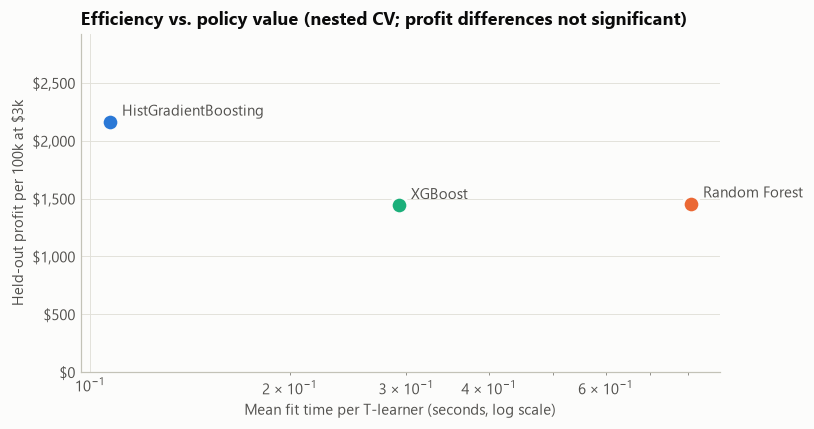

In [10]:
fig, ax = plt.subplots(figsize=(7.5, 4))
for name, r in eff.iterrows():
    ax.scatter(r.mean_fit_s, r["held-out profit @ $3k (mean of campaigns)"], s=120, color=BASE_COLORS[name],
               edgecolor=P.SURFACE, linewidth=2, zorder=3)
    ax.annotate(name, (r.mean_fit_s, r["held-out profit @ $3k (mean of campaigns)"]), xytext=(8, 4),
                textcoords="offset points", fontsize=9.5, color=P.INK_2)
ax.set_xscale("log"); ax.grid(axis="x")
ax.set_xlabel("Mean fit time per T-learner (seconds, log scale)")
ax.set_ylabel("Held-out profit per 100k at $3k"); P.dollar(ax, "y", 0)
ax.set_ylim(0, eff["held-out profit @ $3k (mean of campaigns)"].max() * 1.35)
ax.set_title("Efficiency vs. policy value (nested CV; profit differences not significant)")
fig.tight_layout(); P.savefig(fig, "07_efficiency_vs_value"); plt.show()

## 5 · Winner (pre-declared rule)

In [11]:
main = pol[pol.budget == "$3,000"]
mean_profit = main.groupby("base")["profit"].mean().reindex([bm.NAMES[b] for b in bm.ORDER])
winner = mean_profit.idxmax()
# paired difference of the winner vs the baseline, pooled over both campaigns (each customer counts once per campaign)
z_by = {}
for b in bm.ORDER:
    z_by[b] = np.concatenate([bm.policy_contributions(tau[f"{b}|{c}"], gamma[c].to_numpy())[0] for c in config.CAMPAIGNS])
inv = {v: k for k, v in bm.NAMES.items()}
pairs = {}
for b in ["xgb", "hgb"]:
    d = evaluation.mean_ci(z_by[b] - z_by["rf"])
    pairs[bm.NAMES[b]] = {k: d[k] * config.POPULATION_SIZE for k in ["estimate", "ci_low", "ci_high"]} | {"z": d["estimate"] / d["se"]}
pairs = pd.DataFrame(pairs).T
study = {
    "protocol": "T-learner, 6-config grid per base, inner 3-fold CV on budgeted profit, outer 5-fold nested held-out AIPW",
    "roles": {bm.NAMES[b]: bm.ROLES[b] for b in bm.ORDER},
    "nested_mean_profit_3k": mean_profit.to_dict(),
    "winner": winner,
    "paired_vs_rf_mean_of_campaigns": pairs.to_dict(orient="index"),
    "efficiency": eff[["mean_fit_s", "mean_predict_s", "fit time vs HistGB"]].to_dict(orient="index"),
    "nested_policy": pol.to_dict(orient="records"),
    "nested_ranking": rank.to_dict(orient="records"),
    "test_policy": pol_test.to_dict(orient="records"),
    "test_ranking": rank_test.to_dict(orient="records"),
    "test_split_configs": {bm.NAMES[b]: bm.cfg_label(c) for b, c in test_cfg.items()},
    "nested_configs": chosen.to_dict(orient="records"),
}
with open(config.ARTIFACTS_DIR / "base_learner_study.json", "w") as f:
    json.dump(study, f, indent=2, default=float)
display(mean_profit.to_frame("held-out profit per 100k @ $3k, mean of campaigns").style.format(P.money0))
display(pairs.style.format({"estimate": P.money0, "ci_low": P.money0, "ci_high": P.money0, "z": "{:.2f}"}).set_caption(
    "Paired difference vs Random Forest baseline (both campaigns pooled)"))
print("WINNER:", winner)

,"held-out profit per 100k @ $3k, mean of campaigns"
base,
Random Forest,"$1,457"
XGBoost,"$1,443"
HistGradientBoosting,"$2,164"


,estimate,ci_low,ci_high,z
XGBoost,−$14,"−$3,168","$3,140",-0.01
HistGradientBoosting,$707,"−$2,444","$3,858",0.44


WINNER: HistGradientBoosting


## 6 · Conclusions

In [12]:
p3 = main.set_index(["campaign", "base"])
rk = rank.set_index(["campaign", "base"])
e = eff
RF, XG, HG = bm.NAMES["rf"], bm.NAMES["xgb"], bm.NAMES["hgb"]
def sig(name):
    r = pairs.loc[name]
    return "statistically significant" if abs(r.z) > 1.96 else "not statistically significant"
display(P.md(f"""
**Winner by the pre-declared rule: {winner}** (held-out profit {P.money0(mean_profit[winner])} per 100k at the \\$3k budget, mean of both campaigns).

| | {RF} (baseline) | {XG} (primary candidate) | {HG} (efficiency benchmark) |
|---|---|---|---|
| Held-out profit @ \\$3k, Women's | {P.money0(p3.loc[('womens', RF), 'profit'])} | {P.money0(p3.loc[('womens', XG), 'profit'])} | {P.money0(p3.loc[('womens', HG), 'profit'])} |
| Held-out profit @ \\$3k, Men's | {P.money0(p3.loc[('mens', RF), 'profit'])} | {P.money0(p3.loc[('mens', XG), 'profit'])} | {P.money0(p3.loc[('mens', HG), 'profit'])} |
| Women's AUGC / BLP | {rk.loc[('womens', RF), 'AUGC']:+.3f} / {rk.loc[('womens', RF), 'BLP']:.2f} | {rk.loc[('womens', XG), 'AUGC']:+.3f} / {rk.loc[('womens', XG), 'BLP']:.2f} | {rk.loc[('womens', HG), 'AUGC']:+.3f} / {rk.loc[('womens', HG), 'BLP']:.2f} |
| Mean fit time per T-learner | {e.loc[RF, 'mean_fit_s']:.2f}s ({e.loc[RF, 'fit time vs HistGB']:.1f}×) | {e.loc[XG, 'mean_fit_s']:.2f}s ({e.loc[XG, 'fit time vs HistGB']:.1f}×) | {e.loc[HG, 'mean_fit_s']:.2f}s (1.0×) |

* {XG} − {RF}: {P.money0(pairs.loc[XG, 'estimate'])} per 100k (95% CI {P.money0(pairs.loc[XG, 'ci_low'])} to {P.money0(pairs.loc[XG, 'ci_high'])}), {sig(XG)}.
* {HG} − {RF}: {P.money0(pairs.loc[HG, 'estimate'])} per 100k (95% CI {P.money0(pairs.loc[HG, 'ci_low'])} to {P.money0(pairs.loc[HG, 'ci_high'])}), {sig(HG)}.
"""))


**Winner by the pre-declared rule: HistGradientBoosting** (held-out profit \$2,164 per 100k at the \$3k budget, mean of both campaigns).

| | Random Forest (baseline) | XGBoost (primary candidate) | HistGradientBoosting (efficiency benchmark) |
|---|---|---|---|
| Held-out profit @ \$3k, Women's | \$3,780 | \$1,667 | \$3,854 |
| Held-out profit @ \$3k, Men's | −\$867 | \$1,219 | \$474 |
| Women's AUGC / BLP | +0.070 / 0.15 | -0.012 / -0.01 | +0.052 / 0.05 |
| Mean fit time per T-learner | 0.81s (7.5×) | 0.29s (2.7×) | 0.11s (1.0×) |

* XGBoost − Random Forest: −\$14 per 100k (95% CI −\$3,168 to \$3,140), not statistically significant.
* HistGradientBoosting − Random Forest: \$707 per 100k (95% CI −\$2,444 to \$3,858), not statistically significant.


### Interpretation

1. **At the \$3k budget, the three base learners are statistically tied.** HistGradientBoosting wins on the point estimate, as the pre-declared rule requires, but its edge over the Random Forest baseline is a fraction of one standard error. XGBoost, the primary candidate, does **not** beat the baseline.
2. **Without a budget, Random Forest is best, and XGBoost is clearly worst.** With no budget, the policy depends on the *size* of each predicted effect: who clears the break-even line m·τ̂ > c, not just who ranks first. XGBoost's dollar predictions are the least calibrated (Women's BLP ≈ 0). It e-mails fewer of the right customers and loses about \$3–5k per 100k against the baseline (z ≈ −1.8 to −1.9). Bagging's natural shrinkage makes Random Forest's effect sizes the safest for thresholding.
3. **Ranking agrees with the profit story.** On Women's held-out AUGC, the order is Random Forest (+0.070) > HistGB (+0.052) > XGBoost (−0.012). On Men's, every T-learner is below random, consistent with the absence of Men's heterogeneity (notebook 01).
4. **Efficiency.** HistGradientBoosting fits a T-learner in about 0.11 s, which is **2.7× faster than XGBoost and 7.5× faster than Random Forest**. It also predicts 18× faster than the forest, which scores through 300 deep trees. For the same (statistically tied) policy value, it is the most efficient choice by a wide margin.
5. **Tuning stability.** HistGB chose `max_leaf_nodes=7` in every outer fold. Random Forest and XGBoost changed configuration from fold to fold, a sign that their performance is more sensitive to tuning on this noisy outcome.
6. **Why "the strongest algorithm" did not win.** XGBoost's advantages (second-order boosting, flexible regularization) pay off when there is signal to fit. With 0.9% buyers, a T-learner differences two noisy outcome models, and the base learner that **fits the least noise** wins. Here that is early-stopped histogram boosting or bagging, not aggressive boosting.

**Decision:** keep **HistGradientBoosting** as the T-learner base learner. It is the pre-declared winner, the fastest, and the most tuning-stable. Use Random Forest when the policy relies on break-even thresholds (no budget cap). Do not adopt XGBoost for this outcome without early stopping and a held-out re-test.

*Caveat:* this study ranks base learners **for T-learners on this outcome**. Notebook 03 §4c found Random Forest stronger on calibration when every learner used fixed default settings. Here each base learner was tuned on budgeted profit, and the held-out ranking shifted. That shift is itself evidence that the differences are small relative to noise.